# Python для ИИ: NumPy, Pandas, Matplotlib

Python — язык, на котором записываются действия программы. Библиотеки добавляют готовые средства: **NumPy** хранит массивы и выполняет операции над ними, **Pandas** работает с таблицами с именованными столбцами, **Matplotlib** строит рисунки по подготовленным значениям. Эти средства используются рядом с моделями ИИ: до обращения к модели и при просмотре результатов её работы.

В примерах используется небольшой вымышленный журнал запросов к сервису обработки текста, изображений и аудио. Все значения уже подготовлены внутри ноутбука; внешние файлы и доступ к сети для выполнения примеров не нужны.

Предварительное знание Python не требуется. **Перед каждым блоком кода** описано, что он делает. **После кода и его результата** разобраны переменные, знаки, функции и параметры. В материале представлены выполненные примеры, без заданий. Результаты и рисунки сохранены, поэтому ноутбук можно читать без запуска.

**Содержание**

- [1. Среда и базовые конструкции Python](#python)
- [2. NumPy: устройство массивов и работа с элементами](#numpy)
- [3. Pandas: таблицы, подписи и выбор данных](#pandas)
- [4. Matplotlib: рисунок как объект программы](#matplotlib)
- [5. Совместное использование трёх библиотек](#together)

<a id="python"></a>
## 1. Среда и базовые конструкции Python

### 1.1. Ячейка, ядро и подключение библиотек

Ноутбук состоит из текстовых ячеек и ячеек кода. Текст объясняет действия, код исполняется Python. **Ядро** — работающий процесс Python, в памяти которого сохраняются переменные и подключённые библиотеки. Ячейки этого файла связаны: последующие примеры используют имена, созданные выше.

В Jupyter сочетание `Shift+Enter` выполняет выбранную ячейку и переходит к следующей. Команда меню **Restart Kernel and Run All Cells** или её аналог перезапускает ядро и выполняет весь файл сверху вниз. Название команды может отличаться в разных редакторах. Такой запуск убирает зависимость от случайного порядка предыдущих выполнений.

Библиотека должна быть установлена в среде, выбранной для ядра. Подключение через `import` делает её доступной программе, но не устанавливает её. Для этого файла нужны NumPy, Pandas и Matplotlib; средства `display` входят в среду IPython, используемую Jupyter.

Первый блок подключает три библиотеки, включает показ рисунков под ячейками и задаёт небольшой набор настроек оформления. Вывод версий показывает, какие установленные NumPy и Pandas фактически используются текущим ядром.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (9, 4.5)
plt.rcParams['figure.constrained_layout.use'] = True

print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)

NumPy: 2.4.6
Pandas: 2.3.3


**Разбор кода.**

- `%matplotlib inline` — специальная команда Jupyter, которая включает вывод рисунков внутри ноутбука. Начальный `%` здесь обозначает команду среды. Остальные строки — обычный код Python.
- `import` подключает модуль или библиотеку. Модуль — готовый набор средств; библиотека обычно объединяет несколько таких наборов. `import numpy as np` даёт NumPy короткое имя `np`, а `import pandas as pd` даёт Pandas имя `pd`. Слово `as` означает «использовать под именем».
- `matplotlib.pyplot` — часть Matplotlib для построения рисунков; после `as plt` к ней можно обращаться через `plt`. Точка разделяет уровни имени: библиотеку и её часть.
- `from IPython.display import display` подключает отдельно функцию `display`. **Функция** выполняет действие при вызове. Эта функция удобно показывает таблицы в оформленном виде; она будет использована ниже.
- Текст между одинарными или двойными кавычками — **строка**, то есть текстовое значение. Например, `'font.family'` — имя настройки, `'DejaVu Sans'` — название шрифта. Точки внутри кавычек остаются обычными символами текста.
- `plt.rcParams` — объект настроек рисунков. Квадратные скобки с текстовым ключом выбирают настройку: `['font.family']` — семейство шрифта. Знак `=` меняет выбранное значение. Это присваивание: сначала берётся правая часть, затем сохраняется слева.
- `(9, 4.5)` — **кортеж**, упорядоченная группа значений. Здесь это ширина и высота рисунка в дюймах. Запятая разделяет элементы. Число `9` целое, `4.5` дробное; в Python десятичная часть отделяется точкой.
- `True` — логическое значение «истина». В настройке автоматического размещения оно включает подбор отступов для подписей. Противоположное значение — `False`, «ложь». Названия чувствительны к регистру букв.
- `print(...)` — встроенная функция вывода. Круглые скобки означают вызов, значения внутри — **аргументы**. В `print('NumPy:', np.__version__)` первый аргумент — подпись, второй — значение версии. Запятая разделяет аргументы; в результате между ними появится пробел.
- `np.__version__` и `pd.__version__` — **атрибуты**, хранящие версии библиотек. Атрибут выбирается через точку. Двойные подчёркивания — часть готового имени, их нужно сохранить. Для чтения атрибута круглые скобки не нужны, для вызова функции нужны.

Python исполняет строки сверху вниз. Пустые строки разделяют части кода для читателя и ничего не вычисляют. Подключённые имена `np`, `pd`, `plt`, `display` теперь доступны следующим ячейкам.

### 1.2. Значения и переменные

Программа хранит текст, числа и признаки состояния. **Переменная** — имя, по которому можно получить сохранённое значение. **Тип** определяет, что это за значение и какие действия с ним допустимы. Например, текст названия и число запросов имеют разные типы.

Имена переменных пишутся без пробелов. В этом файле слова в именах разделены подчёркиванием; это обычный способ сделать имя читаемым. Английское имя не меняет смысл хранящегося русского текста.

Следующий блок сохраняет название сервиса, число запросов в очереди и признак его готовности. Затем значения и их типы выводятся отдельно: так видно различие между текстом, целым числом и логическим состоянием.

In [2]:
service_name = 'Учебный сервис'
queued_tasks = 3
is_ready = True

print('Сервис:', service_name)
print('В очереди:', queued_tasks)
print('Готов к работе:', is_ready)
print('Тип названия:', type(service_name))
print('Тип количества:', type(queued_tasks))
print('Тип состояния:', type(is_ready))

Сервис: Учебный сервис
В очереди: 3
Готов к работе: True
Тип названия: <class 'str'>
Тип количества: <class 'int'>
Тип состояния: <class 'bool'>


**Разбор кода.**

- В строке `service_name = 'Учебный сервис'` справа находится строковое значение, слева — выбранное для него имя. Один знак `=` сохраняет значение под этим именем. Кавычки ограничивают текст и сами в значение не входят.
- `queued_tasks = 3` сохраняет целое число, а `is_ready = True` — логическое значение. Кавычек вокруг `3` и `True` нет. Запись `'3'` создала бы текст, а `'True'` — строку из букв, а не логическое состояние.
- Имена `service_name`, `queued_tasks`, `is_ready` означают соответственно название сервиса, очередь и готовность. Это имена автора, не специальные команды языка. При повторном обращении написание должно совпадать полностью.
- `print('Подпись:', переменная)` получает текст и значение переменной, затем выводит их в одной строке. Каждая строка `print` даёт отдельную строку результата.
- `type(...)` — встроенная функция определения типа. В `print(..., type(service_name))` сначала вызывается внутренняя функция `type`, её результат передаётся внешней функции `print`.
- В выводе `<class 'str'>` означает строковый тип, `<class 'int'>` — целочисленный, `<class 'bool'>` — логический. Слово `class` здесь часть представления типа; писать его для создания этих значений не требовалось.

Один и тот же способ присваивания сохраняет значения разных типов. При дальнейшей работе важно учитывать не только имя, но и тип значения за ним.

### 1.3. Списки, кортежи и словари

Несколько значений удобно объединять в коллекцию. **Список** хранит элементы в порядке и позволяет менять состав. **Кортеж** также хранит порядок, но его элементы нельзя заменить присваиванием по индексу. **Словарь** хранит пары «ключ — значение»: например, имя поля и его содержимое.

Позиции в списках и кортежах нумеруются с нуля. Словарь чаще читается по смысловому ключу, например по имени поля статуса. Это различие понадобится при переходе от массивов NumPy к таблицам Pandas.

В этом блоке список содержит виды обработки, кортеж — идентификаторы запросов, а словарь — поля одного запроса. Код показывает обращение по позиции и по ключу, добавление элемента в список и изменение значения поля словаря.

In [3]:
task_kinds = ['Текст', 'Изображение', 'Аудио']
task_ids = ('R001', 'R002', 'R003')
task = {'task_id': 'R001', 'kind': 'Текст', 'status': 'готово'}

print('Первый вид:', task_kinds[0])
print('Последний идентификатор:', task_ids[-1])
print('Статус:', task['status'])

task_kinds.append('Видео')
task['status'] = 'проверено'
print('Список после добавления:', task_kinds)
print('Запрос после изменения:', task)

Первый вид: Текст
Последний идентификатор: R003
Статус: готово
Список после добавления: ['Текст', 'Изображение', 'Аудио', 'Видео']
Запрос после изменения: {'task_id': 'R001', 'kind': 'Текст', 'status': 'проверено'}


**Разбор кода.**

- `[...]` создаёт список, `(...)` с запятыми — кортеж. В обоих случаях запятые разделяют элементы; строки внутри кавычек остаются самостоятельными текстовыми значениями.
- `{...}` создаёт словарь. В записи `'task_id': 'R001'` двоеточие отделяет ключ от значения. Между парами стоят запятые. Ключи `task_id`, `kind`, `status` здесь означают идентификатор, вид и статус запроса.
- Квадратные скобки **после имени** выбирают элемент, а не создают список. `task_kinds[0]` — первый элемент, потому что отсчёт начинается с нуля. Отрицательный индекс `-1` означает последний элемент; `task_ids[-1]` даёт `'R003'`.
- `task['status']` выбирает значение по текстовому ключу. Здесь ключ не является номером позиции. Обращение к отсутствующему ключу вызвало бы ошибку, поэтому используется реально заданное имя поля.
- `task_kinds.append('Видео')` вызывает **метод** списка. Метод — функция, связанная с объектом и вызываемая через точку. `.append(...)` добавляет один элемент в конец существующего списка; записывать результат обратно в `task_kinds` не нужно.
- `task['status'] = 'проверено'` заменяет значение только указанного ключа. Это изменяет существующий словарь. Кортеж `task_ids` в этом примере остаётся неизменным.
- Вызовы `print(...)` до и после изменений показывают разные состояния объектов. Текст в кавычках служит подписью, а значение после запятой читается в момент соответствующего вызова.

Метод может менять объект, как `.append`, а может возвращать новый результат. Это поведение определяется конкретным методом; его нельзя угадывать только по наличию точки в записи.

### 1.4. Условие, функция и повторение действий

**Условие** позволяет выбрать действие по состоянию запроса. **Функция** объединяет действия под именем и получает исходные значения через параметры. **Цикл** повторяет действия для элементов коллекции.

В Python принадлежность строки к условию, функции или циклу задаётся отступом. Двоеточие начинает такой блок, а строки с одинаковым отступом относятся к одному уровню. В примерах используется четыре пробела на уровень.

Следующий блок определяет функцию, которая переводит статус запроса в понятное сообщение. Затем одна и та же функция вызывается для трёх статусов в цикле; для каждого статуса выводится своя строка с пояснением.

In [4]:
def describe_status(status):
    if status == 'готово':
        return 'Результат доступен'
    else:
        return 'Результат пока недоступен'

statuses = ['готово', 'в работе', 'ожидает']
for status in statuses:
    message = describe_status(status)
    print(f'{status}: {message}')

готово: Результат доступен
в работе: Результат пока недоступен
ожидает: Результат пока недоступен


**Разбор кода.**

- `def describe_status(status):` определяет функцию с именем `describe_status`. Имя `status` в скобках — **параметр**, то есть локальное имя для значения, которое передадут при вызове. Определение не обрабатывает конкретный статус до вызова функции.
- `if status == 'готово':` проверяет условие. Два знака `==` сравнивают значения и дают `True` или `False`. Один знак `=` использовался для присваивания и здесь не заменяет сравнение.
- При истинном условии выполняется строка после `if`, при ложном — блок после `else`. Двоеточия начинают блоки; отступ в восемь пробелов у `return` показывает вложение условия внутрь функции.
- `return '...'` завершает работу текущего вызова и возвращает строку вызывающему коду. Возвращённая строка не печатается автоматически. Для показа результата далее используется `print`.
- `statuses = [...]` создаёт список. `for status in statuses:` последовательно берёт каждый его элемент и сохраняет в переменную `status`. Строки с отступом выполняются для каждого элемента; это тело цикла.
- `message = describe_status(status)` вызывает функцию. Фактический текущий статус — **аргумент** вызова; внутри функции он доступен через параметр с тем же именем. Возвращённое сообщение сохраняется в `message`.
- Буква `f` перед кавычкой включает **форматируемую строку**. В `{status}` и `{message}` подставляются значения переменных, а двоеточие между фигурными скобками остаётся обычным текстом.
- `print(...)` выводит одну готовую строку на каждой итерации. Пустая строка между определением функции и списком отделяет части кода для чтения.

Для статуса «готово» выбрана первая ветвь, для двух остальных — ветвь `else`. Один код функции используется трижды с разными входными значениями.

<a id="numpy"></a>
## 2. NumPy: устройство массивов и работа с элементами

### 2.1. Массив и его свойства

Основной объект NumPy — **массив `ndarray`**. Он хранит элементы в одной или нескольких осях. У обычного числового массива все элементы используют один тип хранения; это отличает его от списка Python, который может содержать разные объекты.

**Форма** сообщает длину каждой оси, **число измерений** — сколько осей есть, **размер** — сколько всего элементов. Здесь «измерение» означает устройство контейнера, а не физическую единицу вроде секунды. Тип хранения определяет, например, сохраняются целые или дробные числа.

Следующий блок хранит количество файлов в четырёх запросах в одномерном массиве. Он выводит данные, тип хранения, число осей, форму и размер, а в конце превращает массив обратно в обычный список Python.

In [5]:
file_counts = np.array([1, 3, 2, 4], dtype=np.int64)

print('Количество файлов:', file_counts)
print('Тип элементов:', file_counts.dtype)
print('Число осей:', file_counts.ndim)
print('Форма:', file_counts.shape)
print('Всего элементов:', file_counts.size)
print('Обычный список:', file_counts.tolist())

Количество файлов: [1 3 2 4]
Тип элементов: int64
Число осей: 1
Форма: (4,)
Всего элементов: 4
Обычный список: [1, 3, 2, 4]


**Разбор кода.**

- `np.array(...)` создаёт массив NumPy из переданных данных. Список `[1, 3, 2, 4]` задаёт порядок значений. Внешние круглые скобки относятся к вызову функции, внутренние квадратные — к списку.
- `dtype=np.int64` — **именованный аргумент**: слева имя параметра, справа желаемый тип. `np.int64` задаёт целые числа с 64-битным хранением. Это не строка, поэтому кавычек нет. Явный тип делает выбор хранения видимым в коде.
- `file_counts = ...` сохраняет созданный объект под именем. Подчёркивание соединяет слова «число файлов». В имени массива нет информации о его длине, длина хранится в самом объекте.
- `.dtype`, `.ndim`, `.shape`, `.size` — атрибуты массива. Они соответственно возвращают тип элементов, количество осей, длины осей и общее количество элементов. Атрибуты читаются без круглых скобок.
- Форма `(4,)` — кортеж из одного числа. Запятая показывает, что это именно кортеж, а не число 4 в скобках. Он описывает одну ось из четырёх элементов.
- `file_counts.tolist()` вызывает метод превращения в обычный список. Скобки обязательны для вызова, хотя дополнительных аргументов нет. Исходный массив остаётся массивом, поскольку его имя не переназначалось.
- `print(...)` выводит подпись и соответствующее значение. У массива в выводе могут отсутствовать запятые между элементами; у списка они есть. Различается оформление объектов, а не сами количества файлов.

Массив содержит четыре элемента и одну ось. Тип `int64` подходит именно для целых количеств; к выбору дробного типа вернёмся в примере преобразования типа.

### 2.2. Позиции, строки, столбцы и срезы

У двумерного массива две оси: первая соответствует строкам, вторая — столбцам. Выбор по двум индексам задаёт сначала строку, затем столбец. **Срез** выбирает последовательный участок оси; его правая граница не включается.

В следующем массиве каждая строка описывает пакет запросов. Столбцы в фиксированном порядке содержат количества файлов трёх видов: текст, изображения, аудио. Названия столбцов хранятся в пояснении: сам массив NumPy не добавляет к ним подписи Pandas.

Этот блок создаёт три строки по три значения и показывает несколько вариантов выбора. Отдельно выводятся одно значение, последняя строка, столбец изображений, первые две строки и часть первой строки; так различаются индекс и срез.

In [6]:
batch_files = np.array([
    [2, 1, 0],
    [1, 0, 2],
    [3, 2, 1],
], dtype=np.int64)

print('Все пакеты:\n', batch_files)
print('Текстовых файлов во втором пакете:', batch_files[1, 0])
print('Последняя строка:', batch_files[-1])
print('Столбец изображений:', batch_files[:, 1])
print('Первые две строки:\n', batch_files[:2])
print('Часть первой строки:', batch_files[0, 1:3])

Все пакеты:
 [[2 1 0]
 [1 0 2]
 [3 2 1]]
Текстовых файлов во втором пакете: 1
Последняя строка: [3 2 1]
Столбец изображений: [1 0 2]
Первые две строки:
 [[2 1 0]
 [1 0 2]]
Часть первой строки: [1 0]


**Разбор кода.**

- `np.array([[...], [...], [...]])` получает внешний список, состоящий из трёх внутренних списков. Каждый внутренний список становится строкой. Они имеют одинаковую длину. `dtype=np.int64` явно выбирает целые значения.
- Запятые разделяют строки и элементы. Запятая после последней строки допустима и не создаёт лишнюю пустую строку. Переносы внутри незакрытых скобок продолжают одну инструкцию.
- `batch_files[1, 0]` использует два индекса: строка с номером 1 — вторая, столбец с номером 0 — первый. Результат одно число 1.
- `batch_files[-1]` выбирает всю последнюю строку. Один индекс у двумерного массива относится к первой оси.
- В `batch_files[:, 1]` знак `:` означает все строки, а `1` — второй столбец. Получается одномерный массив значений по всем пакетам.
- `batch_files[:2]` берёт строки с индексами 0 и 1, но не 2. Пропущенное начало означает начало массива. Такой выбор остаётся двумерным, потому что выбраны две целые строки.
- `batch_files[0, 1:3]` выбирает первую строку и столбцы с индексами 1 и 2. Двоеточие внутри скобок означает срез, а не начало блока, как после `for` или `if`.
- В строке подписи последовательность `\n` означает перенос строки. Функция `print(...)` поэтому размещает весь двумерный массив ниже текста.

Указанные индексы выбирают данные по положению. Если порядок столбцов изменится, тот же индекс будет выбирать уже другой вид файлов; именованные столбцы Pandas помогут делать выбор по имени.

### 2.3. Создание массива по шаблону и изменение формы

Массив не обязательно перечислять вручную. Можно подготовить контейнер из нулей, заполнить его одним значением или создать последовательность идентификаторов. **Изменение формы** перегруппировывает существующие элементы по осям, сохраняя их общее количество.

Следующий блок готовит нулевые места для двух пакетов, одинаковые лимиты файлов и шесть последовательных идентификаторов. Затем эти шесть идентификаторов размещаются в двух строках по три значения; содержимое остаётся тем же, меняется его организация.

In [7]:
empty_slots = np.zeros((2, 3), dtype=np.int64)
file_limits = np.full(4, 5, dtype=np.int64)
position_ids = np.arange(100, 106)
position_table = position_ids.reshape(2, 3)

print('Пока незаполненные места:\n', empty_slots)
print('Одинаковые лимиты:', file_limits)
print('Последовательность идентификаторов:', position_ids)
print('Та же последовательность по строкам:\n', position_table)
print('Исходная форма:', position_ids.shape)
print('Новая форма:', position_table.shape)

Пока незаполненные места:
 [[0 0 0]
 [0 0 0]]
Одинаковые лимиты: [5 5 5 5]
Последовательность идентификаторов: [100 101 102 103 104 105]
Та же последовательность по строкам:
 [[100 101 102]
 [103 104 105]]
Исходная форма: (6,)
Новая форма: (2, 3)


**Разбор кода.**

- `np.zeros((2, 3), dtype=np.int64)` создаёт массив из нулей. Внешние круглые скобки вызывают функцию, внутренние `(2, 3)` передают форму одним кортежем: две строки, три столбца. Параметр `dtype` задаёт тип элементов.
- `np.full(4, 5, dtype=np.int64)` создаёт одномерный массив длины 4 и записывает в каждый элемент значение 5. Первое число — размер, второе — заполнитель; это разные аргументы.
- `np.arange(100, 106)` создаёт целую последовательность от 100 до 105. Начало включено, конец 106 не включён; при отсутствии третьего аргумента шаг равен 1.
- `position_ids.reshape(2, 3)` вызывает метод массива и задаёт две строки по три элемента. В новом порядке по строкам сначала идут 100, 101, 102, затем 103, 104, 105.
- `reshape` требует совместимого количества мест: здесь шесть исходных элементов точно заполняют новую форму. При несовпадении количества элементов и мест NumPy сообщил бы об ошибке.
- Результат `.reshape(...)` сохраняется в новое имя `position_table`, исходное `position_ids` по-прежнему обозначает одномерный массив. Меняется форма представления, а не автоматически форма каждого ранее созданного имени.
- `.shape` читает форму без вызова функции. `print(...)` выводит объекты и подписи, а `\n` переносит двумерные массивы ниже подписей.

Нули здесь означают подготовленные места без добавленных файлов. Это выбранный смысл примера: NumPy хранит значения и не определяет за автора, что именно означает ноль.

### 2.4. Действие над массивом, условие и преобразование типа

NumPy умеет применять операцию сразу к массиву. Результатом сравнения становится **логическая маска** — массив значений `True` и `False`. Маска позволяет выбрать элементы, которые удовлетворяют условию.

При преобразовании типа меняется способ представления значений, а не их смысл в программе. Например, целые количества можно представить дробным типом, если такой формат требуется другому компоненту.

Этот блок использует уже заданные количества файлов. Он подготавливает значения с одним дополнительным файлом, выбирает запросы с нужным количеством и создаёт дробную версию исходного массива. Оригинал выводится отдельно, чтобы отличить новый результат от изменения старых данных.

In [8]:
with_attachment = file_counts + 1
large_mask = file_counts >= 3
middle_mask = (file_counts >= 2) & (file_counts <= 3)
fractional_counts = file_counts.astype(np.float64)

print('Исходный массив:', file_counts)
print('С дополнительным файлом:', with_attachment)
print('Маска «не меньше трёх»:', large_mask)
print('Выбранные значения:', file_counts[large_mask])
print('От двух до трёх включительно:', file_counts[middle_mask])
print('Дробный тип:', fractional_counts.dtype, fractional_counts)

Исходный массив: [1 3 2 4]
С дополнительным файлом: [2 4 3 5]
Маска «не меньше трёх»: [False  True False  True]
Выбранные значения: [3 4]
От двух до трёх включительно: [3 2]
Дробный тип: float64 [1. 3. 2. 4.]


**Разбор кода.**

- `file_counts` создан выше. В `file_counts + 1` оператор `+` применяется к каждому элементу массива NumPy. Результат сохраняется в `with_attachment`. Это отличается от `+` для обычных списков Python, где он соединяет списки.
- `file_counts >= 3` сравнивает каждый элемент с 3. Знак `>=` читается «больше или равно». В `large_mask` сохраняется массив `[False, True, False, True]`, а не одно общее логическое значение.
- `file_counts[large_mask]` выбирает элементы на позициях с `True`. Порядок выбранных элементов сохраняется; здесь получаются 3 и 4.
- Знак `<=` означает «меньше или равно». В `(file_counts >= 2) & (file_counts <= 3)` символ `&` объединяет две маски поэлементно: выбранное место должно пройти оба условия. Круглые скобки вокруг сравнений нужны для правильного порядка операций.
- Обычное слово Python `and` не используется для объединения таких массивов условий: оно предназначено для другой логики выбора истинности, а здесь требуется поэлементная операция `&`.
- `.astype(np.float64)` вызывает метод преобразования типа и возвращает новый массив. `np.float64` — тип дробных чисел с 64-битным хранением. Окончания `.0` в выводе показывают дробное представление целых значений.
- `.dtype` читает выбранный тип. Вызовы `print(...)` могут принимать несколько значений, поэтому в последней строке рядом показываются и тип, и массив. Кавычки внутри русских подписей — только оформление текста.

Исходный `file_counts` остаётся `[1, 3, 2, 4]`: ни одна строка этого блока не присваивала новое значение его элементам. Изменения результата не следует путать с изменением источника.

### 2.5. Представление и независимая копия

Некоторые действия создают новый контейнер с собственными данными, другие — **представление**, обращающееся к тем же данным. Обычный срез массива NumPy часто является представлением. Изменение его элементов может изменить исходный массив.

Когда часть данных нужна для независимого редактирования, создаётся явная копия. Это различие важно для предсказуемого поведения программы: отдельное имя само по себе ещё не гарантирует отдельного хранения значений.

Следующий блок сначала меняет значение через срез и показывает изменение исходного массива. Затем создаёт копию такого среза, меняет её и снова выводит источник. Две ситуации различаются одним вызовом метода копирования.

In [9]:
source_ids = np.array([101, 102, 103, 104])
shared_ids = source_ids[:2]
shared_ids[0] = 999
print('Источник после изменения среза:', source_ids)

independent_ids = source_ids[:2].copy()
independent_ids[1] = 555
print('Источник после изменения копии:', source_ids)
print('Независимая копия:', independent_ids)

Источник после изменения среза: [999 102 103 104]
Источник после изменения копии: [999 102 103 104]
Независимая копия: [999 555]


**Разбор кода.**

- `np.array([...])` создаёт исходный числовой массив. `source_ids[:2]` выбирает первые два элемента: правый индекс 2 не включается. Имя `shared_ids` получает представление этой части.
- `shared_ids[0] = 999` присваивает значение конкретному элементу. Слева имя и индекс, справа новое число. Поскольку срез связан с теми же данными, первый `print(...)` показывает 999 также в `source_ids`.
- В `source_ids[:2].copy()` сначала выбирается срез, затем у результата вызывается метод `.copy()`. Он создаёт независимый массив. Метод вызывается с пустыми круглыми скобками, так как дополнительные аргументы не передаются.
- `independent_ids[1] = 555` меняет второй элемент копии. Источник на этот раз остаётся `[999, 102, 103, 104]`; копия становится `[999, 555]`.
- Вторая копия создаётся **после** первой правки источника, поэтому её первый элемент изначально уже 999. Порядок строк объясняет это значение; метод копирования не восстанавливает прежние данные.
- Каждое `print(...)` показывает объект в момент вызова. Новое имя переменной и создание независимых данных — разные действия; гарантию независимости в этом примере даёт `.copy()`.

Этот вывод относится к показанному обычному срезу массива. Поведение других способов выбора определяется их собственными правилами, поэтому переносить его на любой объект Python нельзя.

### 2.6. Соединение массивов и новая ось

Наборы одинаково устроенных данных можно соединить двумя способами. **Последовательное соединение** продолжает существующую ось. **Укладка по новой оси** сохраняет отдельные исходные наборы внутри нового измерения.

Параметр `axis` указывает номер оси. Нумерация осей начинается с нуля, как и нумерация элементов. Для двумерного результата ось 0 соответствует строкам, ось 1 — столбцам.

В этом блоке два набора из трёх идентификаторов сначала соединяются в длинную последовательность. Затем они размещаются отдельными строками и отдельными столбцами. Вывод содержимого и форм помогает увидеть разницу между продолжением оси и созданием новой.

In [10]:
first_batch = np.array([101, 102, 103])
second_batch = np.array([201, 202, 203])

all_ids = np.concatenate([first_batch, second_batch])
batch_rows = np.stack([first_batch, second_batch], axis=0)
batch_columns = np.stack([first_batch, second_batch], axis=1)

print('Одна последовательность:', all_ids, all_ids.shape)
print('Наборы по строкам:\n', batch_rows)
print('Форма:', batch_rows.shape)
print('Наборы по столбцам:\n', batch_columns)
print('Форма:', batch_columns.shape)

Одна последовательность: [101 102 103 201 202 203] (6,)
Наборы по строкам:
 [[101 102 103]
 [201 202 203]]
Форма: (2, 3)
Наборы по столбцам:
 [[101 201]
 [102 202]
 [103 203]]
Форма: (3, 2)


**Разбор кода.**

- Два вызова `np.array(...)` создают одномерные массивы одинаковой длины. Имена `first_batch` и `second_batch` означают первый и второй набор.
- В `np.concatenate([first_batch, second_batch])` квадратные скобки собирают уже существующие массивы в список аргументов для соединения. Сама функция получает этот список как один аргумент. По умолчанию используется ось 0.
- `concatenate` для двух таких одномерных массивов возвращает одномерную последовательность из шести элементов. Порядок наборов в списке задаёт порядок идентификаторов.
- `np.stack([...], axis=0)` добавляет новую ось и ставит каждый набор отдельной строкой. `axis` — имя параметра, `0` — переданное значение; это не присваивание переменной с именем `axis` в общей области программы.
- `np.stack([...], axis=1)` добавляет ось в другое место: элементы первого набора образуют первый столбец, второго — второй. Для `stack` формы всех исходных массивов должны совпадать.
- `.shape` показывает формы `(6,)`, `(2, 3)` и `(3, 2)`. Запятые внутри формы разделяют длины осей; число элементов и смысл расположения нужно читать вместе с самой формой.
- `print(...)` выводит подписи, массивы и формы. Последовательность `\n` переносит двумерные результаты на отдельные строки для удобства чтения.

Соединение не присваивает новых элементов исходным `first_batch` и `second_batch`: результаты сохранены под отдельными именами.

<a id="pandas"></a>
## 3. Pandas: таблицы, подписи и выбор данных

### 3.1. DataFrame и Series

**DataFrame** — таблица со строками и именованными столбцами. Разные столбцы могут хранить разные виды значений: текстовый статус, идентификатор, целое количество файлов. **Series** — одномерный набор значений с подписями; например, один столбец DataFrame.

У таблицы есть **индекс** — подписи строк, и **имена столбцов**. Если индекс не указан, Pandas создаёт последовательные подписи 0, 1, 2 и далее. Идентификатор запроса при этом может оставаться обычным отдельным столбцом.

Учебный журнал содержит пять полей:

| Поле | Содержание |
|---|---|
| `task_id` | идентификатор запроса |
| `kind` | вид обрабатываемого содержимого |
| `status` | состояние запроса |
| `file_count` | количество файлов в запросе |
| `worker` | условное имя исполнителя |

Следующий блок собирает журнал из словаря списков и показывает его как таблицу. Затем столбец статуса извлекается двумя способами: как Series и как DataFrame из одного столбца. Значения совпадают, но структура результата различается.

In [11]:
task_data = {
    'task_id': ['R001', 'R002', 'R003', 'R004', 'R005', 'R006', 'R007', 'R008'],
    'kind': ['Текст', 'Изображение', 'Текст', 'Аудио', 'Изображение', 'Текст', 'Аудио', 'Текст'],
    'status': ['готово', 'в работе', 'готово', 'ожидает', 'готово', 'в работе', 'готово', 'ожидает'],
    'file_count': [1, 3, 2, 1, 4, 2, 3, 1],
    'worker': ['Север', 'Юг', 'Север', 'Юг', 'Север', 'Юг', 'Юг', 'Север'],
}
tasks = pd.DataFrame(task_data)
display(tasks)

status_column = tasks['status']
display(status_column)
display(tasks[['status']])

,task_id,kind,status,file_count,worker
0,R001,Текст,готово,1,Север
1,R002,Изображение,в работе,3,Юг
2,R003,Текст,готово,2,Север
3,R004,Аудио,ожидает,1,Юг
4,R005,Изображение,готово,4,Север
5,R006,Текст,в работе,2,Юг
6,R007,Аудио,готово,3,Юг
7,R008,Текст,ожидает,1,Север


0      готово
1    в работе
2      готово
3     ожидает
4      готово
5    в работе
6      готово
7     ожидает
Name: status, dtype: object

,status
0,готово
1,в работе
2,готово
3,ожидает
4,готово
5,в работе
6,готово
7,ожидает


**Разбор кода.**

- `task_data = {...}` создаёт словарь. Текстовый ключ перед двоеточием задаёт имя будущего столбца, список после двоеточия — его значения сверху вниз. Запятые разделяют пары и элементы списков.
- Все пять списков имеют одинаковую длину — восемь элементов. Элементы с одинаковым номером образуют строку одного запроса. Например, первые значения всех списков относятся к `R001`.
- `pd.DataFrame(task_data)` создаёт объект таблицы из словаря. `DataFrame` — имя **класса**, вида объектов; его вызов создаёт конкретную таблицу. Результат присваивается `tasks`.
- `display(tasks)` показывает таблицу в оформленном виде. В ноутбуке функция `display` удобнее `print` для просмотра нескольких таблиц подряд. Она подключена в первой ячейке и вызывается без префикса библиотеки.
- Крайний левый столбец без имени — автоматически созданный индекс 0–7. Он не является столбцом `task_id`: это отдельные подписи строк.
- `tasks['status']` выбирает один столбец по строковому имени и возвращает Series. В выводе Series слева остаются подписи строк, справа — статусы; внизу Pandas также сообщает имя и тип хранения.
- `tasks[['status']]` использует два уровня квадратных скобок. Внутренние `['status']` — **список имён столбцов**, внешние выбирают эти столбцы из таблицы. Результат DataFrame, даже когда в списке только одно имя.
- `status_column = ...` сохраняет выбранную Series под отдельным именем. В этом блоке значения только читаются, присваивания отдельным элементам таблицы нет.

Выбор одного имени и выбор списка имён — два разных интерфейса. Дальнейшая форма результата зависит от этого выбора, а не только от количества видимых значений.

### 3.2. Быстрый просмотр устройства таблицы

Для работы с таблицей полезно видеть её размер, имена полей и тип каждого столбца. Внутренний тип текста может отображаться как `object` или как специальный строковый тип в зависимости от способа создания и версии Pandas. Это описание хранения, а не дополнительная строка данных.

Краткий просмотр и информация о структуре позволяют понять интерфейс уже готовой таблицы, не выводя каждый раз все записи.

Этот блок выводит форму журнала, список имён столбцов, первые три строки и типы полей. В конце выводится компактная справка по таблице: она показывает индекс, число записей и сведения о каждом столбце.

In [12]:
print('Строк и столбцов:', tasks.shape)
print('Имена столбцов:', tasks.columns.tolist())
display(tasks.head(3))
display(tasks.dtypes)
tasks.info()

Строк и столбцов: (8, 5)
Имена столбцов: ['task_id', 'kind', 'status', 'file_count', 'worker']


,task_id,kind,status,file_count,worker
0,R001,Текст,готово,1,Север
1,R002,Изображение,в работе,3,Юг
2,R003,Текст,готово,2,Север


task_id       object
kind          object
status        object
file_count     int64
worker        object
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   task_id     8 non-null      object
 1   kind        8 non-null      object
 2   status      8 non-null      object
 3   file_count  8 non-null      int64 
 4   worker      8 non-null      object
dtypes: int64(1), object(4)
memory usage: 452.0+ bytes


**Разбор кода.**

- `tasks.shape` — атрибут формы: кортеж `(8, 5)` сообщает восемь строк и пять столбцов. Круглые скобки вызова после `.shape` не нужны.
- `tasks.columns` — объект имён столбцов. Его метод `.tolist()` превращает имена в обычный список Python. В цепочке `tasks.columns.tolist()` сначала выбирается атрибут, затем вызывается метод полученного объекта.
- `tasks.head(3)` возвращает первые три строки как новую таблицу для просмотра. Аргумент `3` задаёт число строк. Внутренний вызов выполняется до `display(...)`, который показывает результат.
- `tasks.dtypes` — атрибут, содержащий тип для каждого столбца. Здесь множественное число `dtypes` относится к нескольким столбцам; у массива NumPy использовался единственный `.dtype`.
- `tasks.info()` — метод, который **сам печатает справку**. Его возвращаемое значение — `None`, специальное значение «нет результата». Поэтому оборачивать этот вызов в `print` не нужно: иначе после справки появилась бы отдельная строка `None`.
- В справке `RangeIndex` означает последовательный индекс, `Non-Null Count` — число заполненных значений в поле. В нашем готовом журнале все поля заполнены. Строка памяти описывает размер объекта, а не отдельное наблюдение.
- Функция `print(...)` удобна для коротких подписанных сообщений, `display(...)` — для представлений таблицы и Series. Выбор способа показа не меняет значения в `tasks`.

Первые строки дают представление о содержимом, а справка описывает весь объект. Это разные способы просмотра одной таблицы.

### 3.3. Выбор по имени и по позиции: loc и iloc

**`loc` выбирает по подписям**, **`iloc` — по порядковым позициям**. Пока подписи индекса равны 0, 1, 2, эти способы легко перепутать. После назначения идентификаторов запросов индексом различие становится явным.

В срезе `loc` обе указанные существующие границы включаются. В позиционном срезе `iloc` правая граница не включается, как в списке Python. Упорядоченные уникальные идентификаторы этого примера делают выбор диапазона по подписям однозначным.

Следующий блок сначала выбирает два столбца по именам, затем назначает идентификаторы запросов индексом отдельной таблицы. Один и тот же участок из трёх строк извлекается по подписям и по позициям; отдельно читается одно значение по подписи строки и имени поля.

In [13]:
display(tasks[['task_id', 'kind']])

indexed_tasks = tasks.set_index('task_id')
display(indexed_tasks.loc['R002':'R004', ['kind', 'status']])
display(indexed_tasks.iloc[1:4, [0, 1]])
print('Вид запроса R002:', indexed_tasks.loc['R002', 'kind'])

,task_id,kind
0,R001,Текст
1,R002,Изображение
2,R003,Текст
3,R004,Аудио
4,R005,Изображение
5,R006,Текст
6,R007,Аудио
7,R008,Текст


,kind,status
task_id,,
R002,Изображение,в работе
R003,Текст,готово
R004,Аудио,ожидает


,kind,status
task_id,,
R002,Изображение,в работе
R003,Текст,готово
R004,Аудио,ожидает


Вид запроса R002: Изображение


**Разбор кода.**

- В `tasks[['task_id', 'kind']]` внутренний список задаёт два имени и их порядок в результате. `display(...)` показывает выбранные столбцы.
- `tasks.set_index('task_id')` возвращает таблицу, где значения указанного поля стали подписями строк. По умолчанию само поле больше не остаётся обычным столбцом. Результат сохраняется в `indexed_tasks`; исходный `tasks` не переназначается.
- `.loc[...]` и `.iloc[...]` записываются с **квадратными скобками**, это интерфейсы индексирования, а не обычные вызовы методов через `(...)`.
- В `.loc['R002':'R004', ['kind', 'status']]` часть до запятой выбирает строки, часть после — столбцы. Двоеточие задаёт диапазон подписей, обе границы здесь входят. Список имён оставляет два столбца в указанном порядке.
- В `.iloc[1:4, [0, 1]]` строки выбираются по позициям 1, 2, 3. Столбцы с позициями 0 и 1 после `set_index` — это `kind` и `status`. Номер 4 как правая граница не входит.
- `.loc['R002', 'kind']` выбирает одну строку и одно поле. Результат — одно текстовое значение, которое `print(...)` выводит рядом с подписью.

Два средних вывода содержат одинаковые строки. Совпадение получено разными описаниями выбора: идентификаторами и позициями, а не взаимозаменяемостью `loc` и `iloc` во всех ситуациях.

### 3.4. Выбор строк по условиям

Сравнение столбца с нужным значением создаёт логическую Series. Её можно передать в `loc` вместо списка подписей строк. Такая маска сохраняет индекс исходной таблицы и описывает, какие строки оставить.

Несколько условий объединяются поэлементно. Проверка на принадлежность списку удобна, когда подходит один из нескольких видов содержимого.

Этот блок показывает готовые запросы, затем только готовые текстовые запросы, затем запросы двух выбранных видов. В каждом случае условия создаются отдельно и используются для просмотра нужных строк и полей.

In [14]:
ready_mask = tasks['status'] == 'готово'
display(tasks.loc[ready_mask, ['task_id', 'kind', 'file_count']])

ready_text_mask = (tasks['kind'] == 'Текст') & ready_mask
display(tasks.loc[ready_text_mask])

media_mask = tasks['kind'].isin(['Аудио', 'Изображение'])
display(tasks.loc[media_mask, ['task_id', 'kind', 'status']])

,task_id,kind,file_count
0,R001,Текст,1
2,R003,Текст,2
4,R005,Изображение,4
6,R007,Аудио,3


,task_id,kind,status,file_count,worker
0,R001,Текст,готово,1,Север
2,R003,Текст,готово,2,Север


,task_id,kind,status
1,R002,Изображение,в работе
3,R004,Аудио,ожидает
4,R005,Изображение,готово
6,R007,Аудио,готово


**Разбор кода.**

- `tasks['status']` выбирает Series статусов. Оператор `== 'готово'` сравнивает каждую её запись с текстом. В `ready_mask` сохраняется логическая Series, а не одна общая проверка таблицы.
- `.loc[ready_mask, [...]]` оставляет строки с `True`, затем выбирает столбцы из списка. Внутренний список в квадратных скобках — перечень имён; запятая разделяет выбор строк и столбцов.
- В `ready_text_mask` сравнение вида содержимого заключено в круглые скобки, чтобы сначала получить отдельную маску. `&` выполняет поэлементное «и»: строка должна быть и текстовой, и готовой. Ранее созданная `ready_mask` используется повторно.
- `tasks.loc[ready_text_mask]` задаёт только выбор строк. Поскольку часть после запятой не указана, сохраняются все столбцы.
- `.isin(['Аудио', 'Изображение'])` проверяет каждое значение столбца на наличие в переданном списке. Метод возвращает ещё одну логическую Series. Название можно читать как «находится среди».
- `display(...)` показывает три результата последовательно. Между ними пустые строки в исходном коде помогают различать этапы, но не выполняют действий.

Исходный журнал не заменялся отфильтрованными данными: результаты только передавались в `display`. Полный `tasks` остаётся доступен следующим примерам.

### 3.5. Новый столбец и адресное изменение значения

Выбор данных и их изменение — разные действия. Для самостоятельного редактирования таблицы здесь создаётся явная копия. Новое имя поля слева от присваивания добавляет столбец; выбор строк и поля через `loc` позволяет изменить конкретные записи.

Одна таблица содержит исходные состояния, другая — вариант с дополнительным признаком и изменённым статусом.

Следующий блок делает копию журнала, добавляет признак необходимости проверки для аудио и изображений и меняет статус запроса R003. Затем отдельно выводится исходный статус этого запроса, чтобы проверить независимость редактируемой таблицы.

In [15]:
editable_tasks = tasks.copy()
editable_tasks['needs_review'] = editable_tasks['kind'].isin(['Аудио', 'Изображение'])

target_mask = editable_tasks['task_id'] == 'R003'
editable_tasks.loc[target_mask, 'status'] = 'проверено'

display(editable_tasks[['task_id', 'kind', 'status', 'needs_review']])
display(tasks.loc[tasks['task_id'] == 'R003', ['task_id', 'status']])

,task_id,kind,status,needs_review
0,R001,Текст,готово,False
1,R002,Изображение,в работе,True
2,R003,Текст,проверено,False
3,R004,Аудио,ожидает,True
4,R005,Изображение,готово,True
5,R006,Текст,в работе,False
6,R007,Аудио,готово,True
7,R008,Текст,ожидает,False


,task_id,status
2,R003,готово


**Разбор кода.**

- `tasks.copy()` вызывает метод явного копирования таблицы. В этом журнале поля содержат обычные текстовые и целые значения; `editable_tasks` можно редактировать независимо от `tasks`.
- Слева `editable_tasks['needs_review']` обозначает новый столбец. Справа `.isin([...])` создаёт логическую Series по виду содержимого. Присваивание помещает по одному значению `True` или `False` в соответствующую строку нового столбца.
- Текст `needs_review` — выбранное имя поля, означающее «нужна проверка». Это обычная строка-ключ, а не специальный параметр Pandas.
- `target_mask = ... == 'R003'` создаёт маску нужного идентификатора. В `editable_tasks.loc[target_mask, 'status'] = 'проверено'` часть слева указывает изменяемые ячейки, справа — новое значение. Один текст будет записан во все выбранные строки, здесь в одну.
- `loc` используется для изменения непосредственно в таблице. Сначала создавать отдельную выборку столбца, а затем пытаться менять её повторным индексированием здесь не требуется.
- `display(editable_tasks[[...]])` показывает четыре выбранных поля в заданном порядке. Двойные квадратные скобки сохраняют табличную форму.
- Во втором `display` сравнение написано прямо внутри `.loc[...]`, без отдельного имени маски. Сначала вычисляется условие, затем выбирается строка исходного `tasks` и два её поля.

В копии R003 имеет статус «проверено», в исходной таблице — «готово». Добавленный логический столбец описывает свойство запроса и не является результатом работы модели ИИ.

### 3.6. Порядок строк и подписи индекса

Сортировка меняет порядок строк, но сама по себе не перенумеровывает их индекс. Иногда полезно сохранить прежние подписи, иногда — назначить результату новый последовательный индекс. Это две отдельные операции.

Идентификаторы `R001`–`R008` имеют одинаковый формат с ведущими нулями, поэтому их текстовая сортировка соответствует ожидаемому порядку кодов.

Этот блок сортирует журнал по идентификатору в обратном порядке и показывает первые четыре строки. Затем он создаёт результат с новым индексом и выводит те же записи повторно: сравниваются именно подписи строк, а не содержимое полей.

In [16]:
ordered_tasks = tasks.sort_values('task_id', ascending=False)
display(ordered_tasks.head(4))

renumbered_tasks = ordered_tasks.reset_index(drop=True)
display(renumbered_tasks.head(4))

,task_id,kind,status,file_count,worker
7,R008,Текст,ожидает,1,Север
6,R007,Аудио,готово,3,Юг
5,R006,Текст,в работе,2,Юг
4,R005,Изображение,готово,4,Север


,task_id,kind,status,file_count,worker
0,R008,Текст,ожидает,1,Север
1,R007,Аудио,готово,3,Юг
2,R006,Текст,в работе,2,Юг
3,R005,Изображение,готово,4,Север


**Разбор кода.**

- `tasks.sort_values('task_id', ascending=False)` сортирует по значениям указанного столбца. Первый аргумент — имя поля. `ascending=False` задаёт убывающий порядок; `True` задал бы возрастающий.
- Результат сохраняется в `ordered_tasks`. Вызов не присваивал новое значение исходному `tasks`, поэтому его порядок здесь не меняется.
- `.head(4)` возвращает первые четыре строки уже отсортированного результата. `display(...)` показывает их вместе с прежними подписями индекса: 7, 6, 5, 4.
- `.reset_index(drop=True)` возвращает таблицу с новым последовательным индексом 0, 1, 2 и далее. Параметр `drop=True` просит не превращать старый индекс в дополнительный столбец.
- Во втором имени `renumbered_tasks` сохраняется перенумерованный вариант. Четыре запроса и их порядок совпадают с первым выводом; отличаются подписи слева.

Новый индекс обозначает позицию в текущем представлении, а идентификатор запроса по-прежнему хранится в поле `task_id`. Перенумерация индекса не переименовывает сами запросы.

### 3.7. Подсчёт категорий и группировка записей

Таблица может возвращать не только отдельные строки, но и компактное представление повторяющихся категорий. Один способ — получить число записей каждого вида. Другой — собрать записи одного исполнителя в отдельную группу и вернуть список их идентификаторов.

**Группировка** определяет, какие строки рассматривать вместе. **Агрегирование** определяет, что получить из каждой группы; здесь это обычный список текстовых кодов.

Следующий блок создаёт два кратких представления журнала. Первое содержит количество запросов каждого вида и пригодится для рисунка. Второе перечисляет идентификаторы запросов у каждого исполнителя, сохраняя порядок их появления в журнале.

In [17]:
kind_counts = tasks['kind'].value_counts(sort=False)
display(kind_counts)

task_ids_by_worker = tasks.groupby('worker', sort=False)['task_id'].agg(list)
display(task_ids_by_worker)

kind
Текст          4
Изображение    2
Аудио          2
Name: count, dtype: int64

worker
Север    [R001, R003, R005, R008]
Юг       [R002, R004, R006, R007]
Name: task_id, dtype: object

**Разбор кода.**

- `tasks['kind']` выбирает один столбец как Series. Метод `.value_counts(sort=False)` считает, сколько раз встречается каждое значение. В результате индексом становятся названия видов, значениями — целые количества.
- Параметр `sort=False` отключает сортировку категорий по количеству. Для этих данных остаётся порядок первого появления: текст, изображение, аудио. Результат сохраняется в `kind_counts`.
- `tasks.groupby('worker', sort=False)` создаёт описание групп по столбцу исполнителя. Одинаковые значения `worker` попадают в одну группу. Сам вызов ещё не задаёт, что получить из каждой группы.
- Последующее `['task_id']` оставляет внутри групп нужное поле. Метод `.agg(list)` применяет построение списка к идентификаторам каждой группы и возвращает Series со списками.
- `list` здесь — встроенное средство создания списка, переданное **как действие**, без скобок вызова. Вызывать его для каждой группы будет Pandas. Запись `.agg(list())` имела бы другой смысл: создала бы пустой список заранее и передала бы его вместо действия.
- `sort=False` у `groupby` сохраняет порядок появления групп; порядок строк внутри каждой группы здесь соответствует исходной таблице. Имя `task_ids_by_worker` описывает результат: идентификаторы по исполнителям.
- Два вызова `display(...)` показывают обе Series. Текст в квадратных скобках внутри второго вывода — элементы хранящихся списков, а не новая строка программы.

Дальше `kind_counts` используется как готовый набор подписей и высот для столбчатого рисунка. Отдельная таблица для этих двух частей не требуется.

### 3.8. Подпись строки важнее её текущей позиции

Pandas использует индекс для согласования объектов. Когда таблица собирается из нескольких Series, значения сопоставляются по **одинаковым подписям**, даже если исходные Series перечислены в разном порядке.

Это отличается от поэлементной работы массивов NumPy, где определяющими являются позиции и форма. В следующем примере все подписи присутствуют в обеих Series, поэтому никаких отсутствующих значений не возникает.

Этот блок намеренно записывает исполнителей в порядке, обратном порядку статусов. Затем обе Series собираются в таблицу. По итоговому виду можно проверить, что исполнитель прикрепился к нужному идентификатору запроса, а не к строке с тем же порядковым номером.

In [18]:
status_by_id = pd.Series(['готово', 'ожидает'], index=['R001', 'R002'])
worker_by_id = pd.Series(['Юг', 'Север'], index=['R002', 'R001'])

aligned_tasks = pd.DataFrame({
    'status': status_by_id,
    'worker': worker_by_id,
})
display(aligned_tasks)

,status,worker
R001,готово,Север
R002,ожидает,Юг


**Разбор кода.**

- `pd.Series([...], index=[...])` создаёт Series из списка значений и списка подписей. Элементы двух списков с одинаковым номером задают одну пару «подпись — значение».
- В `status_by_id` готовность относится к `R001`, ожидание — к `R002`. В `worker_by_id` исполнитель «Юг» относится к `R002`, «Север» — к `R001`: это задано аргументом `index`, а не порядком в другой Series.
- `pd.DataFrame({...})` получает словарь, где ключи `'status'`, `'worker'` станут именами столбцов, а значения — уже созданные Series. Фигурные скобки и двоеточия оформляют словарь; строки с отступом продолжают один вызов.
- При создании DataFrame Pandas совмещает одинаковые подписи индекса. Поэтому в строке `R001` оказываются «готово» и «Север», хотя в одной исходной Series эта запись первая, а в другой вторая.
- `display(aligned_tasks)` показывает результат, где идентификаторы находятся слева как индекс. Они не являются отдельным обычным столбцом, поскольку переданы через индексы Series.

Порядок исходных Series можно менять, сохраняя смысл подписей. Передавать данные в библиотеку, работающую только с позициями, следует с осознанным выбором нужного порядка.

### 3.9. Переход между Pandas и NumPy

Многие компоненты принимают массивы NumPy. Метод преобразования таблицы или столбца возвращает значения, но не переносит с ними подписи Pandas. Форму результата определяет исходный объект: Series даёт одну ось, DataFrame из одного столбца — две.

Для обратного создания таблицы можно явно указать столбцы и индекс. Эти подписи нужно передать отдельно, в том же порядке, что и значения массива.

Следующий блок превращает количество файлов в одномерный и двумерный массивы. Он сравнивает их формы и создаёт из двумерного результата новую таблицу с явно переданными именем поля и идентификаторами запросов.

In [19]:
count_values = tasks['file_count'].to_numpy(dtype=np.int64, copy=True)
count_table_values = tasks[['file_count']].to_numpy(dtype=np.int64, copy=True)

print('Массив из Series:', count_values, count_values.shape)
print('Форма массива из DataFrame:', count_table_values.shape)

recreated_counts = pd.DataFrame(
    count_table_values,
    columns=['file_count'],
    index=tasks['task_id'],
)
display(recreated_counts.head(3))

Массив из Series: [1 3 2 1 4 2 3 1] (8,)
Форма массива из DataFrame: (8, 1)


,file_count
task_id,
R001,1
R002,3
R003,2


**Разбор кода.**

- `tasks['file_count']` возвращает Series, `tasks[['file_count']]` — DataFrame. Внутренний список имён в двойных скобках сохраняет табличную форму даже для одного столбца.
- `.to_numpy(dtype=np.int64, copy=True)` превращает выбранный объект в массив NumPy. `dtype` задаёт целый тип, `copy=True` явно запрашивает отдельную копию значений. Здесь все исходные значения уже целые и заполнены.
- Результаты сохраняются в `count_values` и `count_table_values`. Через `.shape` читаются формы `(8,)` и `(8, 1)`. Метод преобразования вызывается с круглыми скобками, атрибут формы — без них.
- `print(...)` показывает значения и формы, чтобы различие не оставалось скрытым. Сами имена полей и запросов внутри этих массивов не хранятся.
- `pd.DataFrame(count_table_values, ...)` создаёт таблицу из двумерного массива. `columns=['file_count']` задаёт список имён столбцов, `index=tasks['task_id']` задаёт подписи строк по текущему порядку идентификаторов.
- Несколько строк внутри незакрытых круглых скобок — один вызов. Запятая после последнего аргумента допустима и не добавляет лишний аргумент.
- `display(recreated_counts.head(3))` сначала выбирает первые три строки новой таблицы, затем показывает их. Исходный `tasks` для этого не изменяется.

Возвращённые подписи выглядят привычно, но они появились из явно переданных `columns` и `index`. В самом NumPy-массиве их не было.

<a id="matplotlib"></a>
## 4. Matplotlib: рисунок как объект программы

### 4.1. Figure, Axes и первый рисунок

**Figure** — рисунок целиком, **Axes** — область внутри него, в которой находятся данные, оси, подписи и заголовок. У одного Figure может быть одна или несколько областей Axes. Разделение позволяет явно указать, куда добавлять очередную линию или подпись.

В примерах данные уже готовы к показу. Мы обращаемся к объектам рисунка и их методам: создаём область, добавляем элементы, задаём оформление и показываем результат.

Следующий блок хранит пять названий дней и пять готовых значений количества запросов. Он строит линию с маркерами, подписывает оси и добавляет легенду; каждая точка соответствует своему дню по порядку в двух наборах.

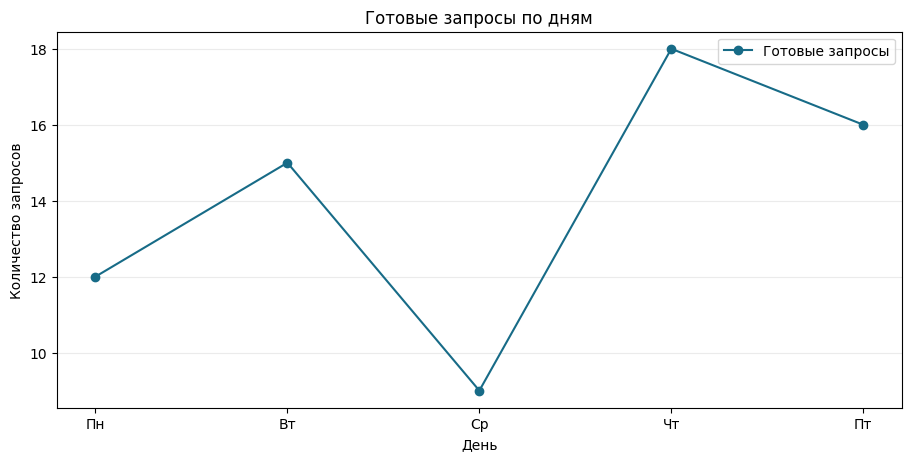

In [20]:
day_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт']
daily_ready = np.array([12, 15, 9, 18, 16])

line_figure, line_axis = plt.subplots()
line_axis.plot(
    day_names, daily_ready,
    marker='o', linestyle='-', color='#176B87', label='Готовые запросы',
)
line_axis.set(
    title='Готовые запросы по дням',
    xlabel='День', ylabel='Количество запросов',
)
line_axis.grid(axis='y', alpha=0.25)
line_axis.legend()
plt.show()

**Разбор кода.**

- `day_names` — список текстовых подписей. `np.array([...])` создаёт массив `daily_ready` из готовых целых количеств. Первый день соответствует первому значению, второй — второму; длины двух наборов должны совпадать.
- `plt.subplots()` возвращает два объекта. Запись `line_figure, line_axis = ...` **распаковывает** их в два имени: весь рисунок и одну область рисования. Имена выбраны для ясности, они не являются обязательными словами Matplotlib.
- `line_axis.plot(day_names, daily_ready, ...)` добавляет линию в указанную область. Первый аргумент задаёт горизонтальные положения или категории, второй — вертикальные значения.
- `marker='o'` рисует круглые маркеры, `linestyle='-'` соединяет их сплошной линией. Это параметры оформления. `color='#176B87'` задаёт цвет текстовым шестнадцатеричным кодом; символ `#` внутри строки не начинает комментарий.
- `label='Готовые запросы'` сохраняет подпись линии для легенды. Метод `.legend()` затем собирает такие подписи и показывает их на рисунке.
- Метод `.set(...)` принимает несколько именованных настроек. `title` задаёт заголовок, `xlabel` — подпись горизонтальной оси, `ylabel` — вертикальной. Слева от `=` внутри вызова стоят имена параметров, справа — их текстовые значения.
- `.grid(axis='y', alpha=0.25)` добавляет линии сетки по вертикальной шкале. `axis='y'` здесь выбирает направление шкалы рисунка; это другой параметр, чем числовой номер оси массива NumPy. `alpha` задаёт прозрачность: 0 полностью прозрачно, 1 непрозрачно.
- `plt.show()` показывает готовый рисунок. Пустые скобки означают вызов без дополнительных аргументов. Несколько строк внутри незакрытых скобок продолжают один вызов; завершающая запятая после последнего аргумента допустима.

Подписи объясняют содержание рисунка без чтения исходных имён переменных. Линия соединяет подготовленные точки; дополнительных значений в таблицу она не добавляет.

### 4.2. Подписи и высоты из Series

Series объединяет две нужные для столбчатого рисунка части: индекс содержит подписи, значения — высоты. Matplotlib может получить их отдельно. Такой переход сохраняет соответствие категорий значениям, если обе части взяты из одного объекта в одном порядке.

Подписи над столбцами относятся к объектам уже построенного рисунка. Для их добавления полезно сохранить результат метода построения.

Этот блок использует ранее подготовленную Series с количеством запросов каждого вида. Названия категорий передаются на горизонтальную ось, количества — в высоты столбцов. Над каждым столбцом добавляется готовое значение, а деления вертикальной оси задаются явно.

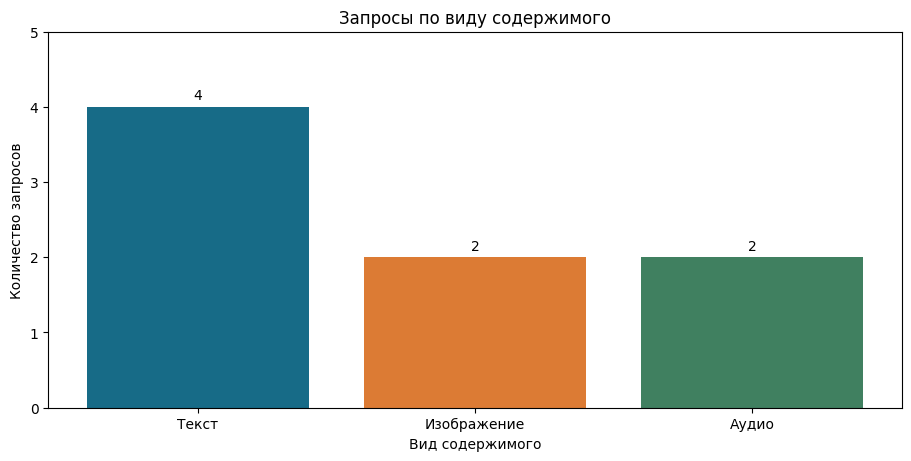

In [21]:
bar_figure, bar_axis = plt.subplots()
bars = bar_axis.bar(
    kind_counts.index,
    kind_counts.to_numpy(),
    color=['#176B87', '#DC7B34', '#408060'],
)
bar_axis.bar_label(bars, padding=3)
bar_axis.set(
    title='Запросы по виду содержимого',
    xlabel='Вид содержимого', ylabel='Количество запросов',
)
bar_axis.set_yticks(range(0, 6))
plt.show()

**Разбор кода.**

- `plt.subplots()` создаёт рисунок `bar_figure` и область `bar_axis`; два результата присваиваются двум именам по порядку.
- `kind_counts` создан в примере подсчёта категорий Pandas. Его атрибут `.index` содержит названия видов. Метод `.to_numpy()` возвращает массив количеств в соответствующем порядке.
- `bar_axis.bar(подписи, высоты, ...)` рисует вертикальные столбцы. Список `color=[...]` задаёт три цвета по порядку; в нашем наборе три категории. Запятые внутри списка разделяют строки с кодами цветов.
- Возвращаемое значение `.bar(...)` сохраняется в `bars`. Это контейнер нарисованных столбцов, с которым можно работать после построения. Он отличается от массива исходных высот.
- `.bar_label(bars, padding=3)` добавляет значения над сохранёнными столбцами. `padding=3` — расстояние текста от края столбца в типографских пунктах; это настройка размещения надписи, а не изменение данных.
- `.set(...)` задаёт заголовок и подписи осей. `.set_yticks(...)` задаёт положения делений вертикальной оси, а не высоты столбцов.
- Встроенное `range(0, 6)` даёт целые значения от 0 до 5, не включая правую границу 6. Это удобный способ передать последовательность делений без ручного перечисления списка.
- `plt.show()` отображает полученный рисунок. Имя `bar_figure` сохраняет сам объект рисунка в памяти независимо от того, какие методы вызваны у его области.

Категории и значения пришли из одной Series: текст — 4 запроса, изображение — 2, аудио — 2. Числа над столбцами позволяют прочитать результат без подбора по шкале.

### 4.3. Точки и поясняющая подпись

Метод рассеяния рисует отдельную точку для каждой пары значений. Порядок двух массивов определяет пары; точка сама по себе не обязана соединяться линией с соседями. Подпись выбранной точки можно разместить со смещением, чтобы она не закрывала маркер.

Ниже используется отдельный маленький набор готовых сведений о четырёх обработанных файлах: размер и время обработки. Значения вымышленные, их назначение — показать интерфейс построения и оформления.

Следующий блок выводит четыре точки по размерам файлов и времени обработки. Первая точка помечается идентификатором F001. Пример показывает передачу двух массивов, настройку внешнего вида маркеров и привязку текстовой подписи к конкретной паре значений.

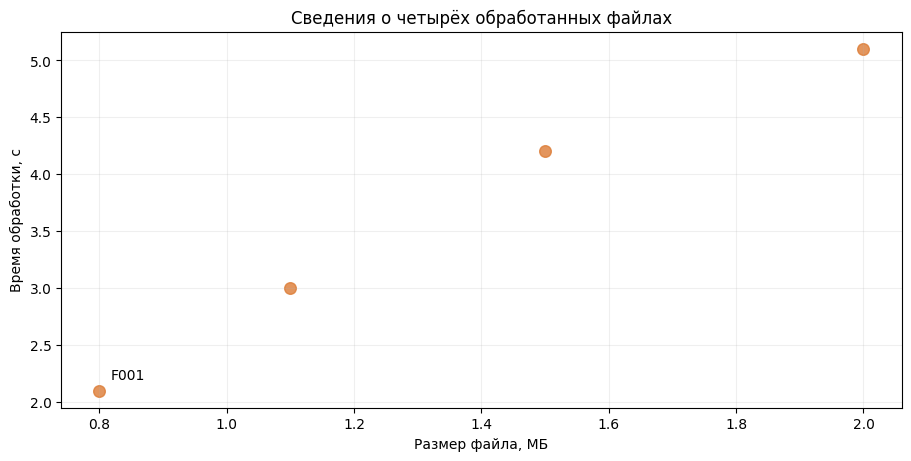

In [22]:
file_sizes_mb = np.array([0.8, 1.5, 1.1, 2.0])
processing_seconds = np.array([2.1, 4.2, 3.0, 5.1])

point_figure, point_axis = plt.subplots()
point_axis.scatter(
    file_sizes_mb, processing_seconds,
    s=70, alpha=0.8, color='#DC7B34',
)
point_axis.annotate(
    'F001',
    (file_sizes_mb[0], processing_seconds[0]),
    xytext=(8, 8), textcoords='offset points',
)
point_axis.set(
    title='Сведения о четырёх обработанных файлах',
    xlabel='Размер файла, МБ', ylabel='Время обработки, с',
)
point_axis.grid(alpha=0.2)
plt.show()

**Разбор кода.**

- Два вызова `np.array(...)` создают массивы дробных чисел. В числовой записи Python используется десятичная точка. Элементы с одинаковым индексом относятся к одному файлу.
- `plt.subplots()` возвращает рисунок и одну область, которые сохраняются в `point_figure`, `point_axis`. Дальше все методы с началом `point_axis.` относятся к этой области.
- `.scatter(file_sizes_mb, processing_seconds, ...)` размещает точки. Первый массив задаёт горизонтальные координаты, второй — вертикальные. Массивы одинаковой длины, поэтому каждая точка получает оба значения.
- `s=70` задаёт площадь маркера в квадратных типографских пунктах, `alpha=0.8` — прозрачность, `color` — цвет. Эти параметры меняют изображение, а не размер и время самих файлов.
- `.annotate('F001', (x, y), ...)` привязывает подпись к точке. В нашем коде `file_sizes_mb[0]` и `processing_seconds[0]` выбирают первые значения; запятая внутри круглых скобок объединяет их в кортеж координат.
- `xytext=(8, 8)` и `textcoords='offset points'` сдвигают текст относительно точки на 8 типографских пунктов вправо и вверх. Это смещение надписи на экране, не изменение координат данных.
- `.set(...)` задаёт заголовок и названия осей с единицами. `.grid(alpha=0.2)` добавляет полупрозрачную сетку по обеим шкалам, потому что направление отдельно не ограничено.
- `plt.show()` выводит готовый рисунок. Значения двух исходных массивов остаются доступны по своим именам.

Одна подпись относится к одной точке, определённой индексом 0. Остальные точки не получают идентификаторов автоматически: для этого потребовались бы дополнительные явные вызовы оформления.

### 4.4. Несколько областей на одном рисунке

Один рисунок может объединять несколько самостоятельных областей. Тогда результат создания содержит коллекцию объектов Axes, и нужная область выбирается по индексу. Общий заголовок принадлежит Figure, заголовок отдельной области — её Axes.

Имена переменных помогают различать целый рисунок и его части. Для двух областей в одну строку удобно использовать имена `summary_figure` и `summary_axes`.

Этот блок размещает рядом два представления журнала: количество запросов у исполнителей и количество запросов разных видов. Левая область использует горизонтальные столбцы, правая — вертикальные. Общий заголовок связывает обе части в один рисунок.

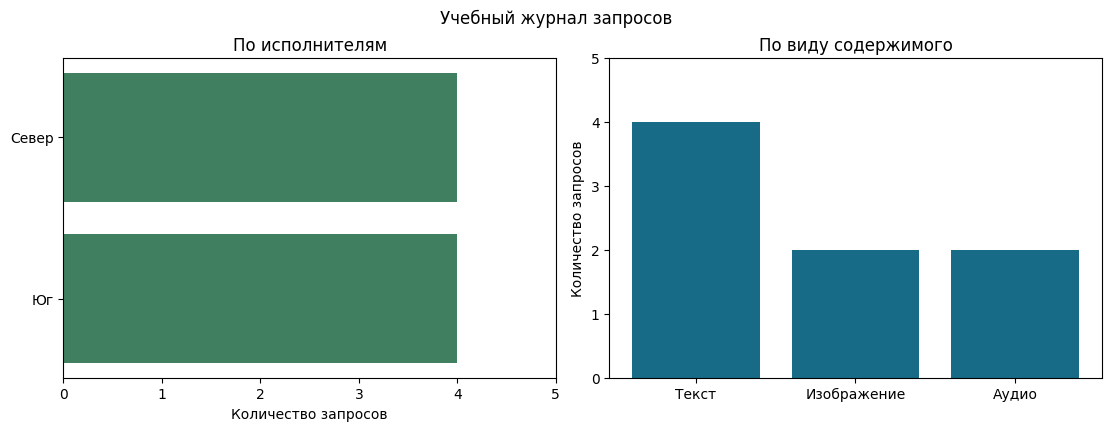

In [23]:
worker_counts = tasks['worker'].value_counts(sort=False)

summary_figure, summary_axes = plt.subplots(1, 2, figsize=(11, 4.2))
summary_axes[0].barh(worker_counts.index, worker_counts.to_numpy(), color='#408060')
summary_axes[0].set(title='По исполнителям', xlabel='Количество запросов')
summary_axes[0].set_xticks(range(0, 6))
summary_axes[0].invert_yaxis()

summary_axes[1].bar(kind_counts.index, kind_counts.to_numpy(), color='#176B87')
summary_axes[1].set(title='По виду содержимого', ylabel='Количество запросов')
summary_axes[1].set_yticks(range(0, 6))

summary_figure.suptitle('Учебный журнал запросов')
plt.show()

**Разбор кода.**

- `tasks['worker'].value_counts(sort=False)` создаёт Series количества записей каждого исполнителя. Сначала выбирается столбец, затем считается число его повторяющихся значений. Порядок категорий сохраняет первое появление.
- `plt.subplots(1, 2, figsize=(11, 4.2))` получает два позиционных аргумента: одну строку и два столбца областей. `figsize` задаёт размер всего рисунка, а не каждой области по отдельности.
- Результаты распаковываются в `summary_figure` и `summary_axes`. Здесь `summary_axes` — массив из двух объектов областей, поэтому `summary_axes[0]` выбирает левую, `[1]` — правую. Отсчёт начинается с нуля.
- `.barh(подписи, длины, ...)` строит горизонтальные столбцы слева. Атрибут `.index` содержит исполнителей, `.to_numpy()` передаёт их количества. Метод `.bar(...)` справа использует тот же принцип передачи данных для вертикальных столбцов.
- `.set(...)` назначает настройки выбранной области. `.set_xticks(range(0, 6))` слева задаёт горизонтальные деления, `.set_yticks(...)` справа — вертикальные. `range` не включает свою правую границу.
- `.invert_yaxis()` меняет направление вертикальной оси слева, чтобы первая категория шла сверху. Метод не переставляет строки в исходном `tasks` и не меняет значения Series.
- `color` получает строковый код цвета. Вызов `.suptitle(...)` сделан у `summary_figure`, поэтому заголовок относится к рисунку целиком, а не только к последней области.
- Один `plt.show()` показывает весь рисунок с обеими областями. Их независимые настройки сохраняются в двух объектах Axes.

Получился один объект Figure с двумя областями. Его можно передать дальше как единый результат программы.

### 4.5. Получение PNG в памяти

Рисунок можно не только показать в ноутбуке, но и преобразовать в изображение для передачи другому компоненту. Для этого объект Figure умеет записывать изображение в файл или в объект, ведущий себя как файл.

**Буфер в памяти** хранит результат без создания отдельного файла на диске. В этом примере получается набор байтов PNG — готовое представление изображения, которое программа могла бы передать дальше.

Следующий блок записывает предыдущий рисунок с двумя областями в буфер, извлекает его содержимое и выводит тип результата и размер. Используется уже существующий объект Figure; рисовать данные повторно для сохранения не требуется.

In [24]:
from io import BytesIO

png_buffer = BytesIO()
summary_figure.savefig(png_buffer, format='png', dpi=140, bbox_inches='tight')
png_bytes = png_buffer.getvalue()

print('Тип результата:', type(png_bytes))
print('Размер изображения:', len(png_bytes), 'байт')

Тип результата: <class 'bytes'>
Размер изображения: 34791 байт


**Разбор кода.**

- `from io import BytesIO` подключает средство стандартной библиотеки Python. `io` — модуль ввода и вывода, `BytesIO` — вид буфера для двоичных данных. Отдельная установка этого модуля не требуется.
- `BytesIO()` создаёт пустой буфер. Скобки означают создание конкретного объекта, имя `png_buffer` сохраняет его для последующих вызовов.
- `summary_figure` — весь рисунок из предыдущего примера. Его метод `.savefig(...)` получает буфер первым аргументом и записывает туда изображение. Передаётся именно объект Figure, поэтому сохраняются обе его области.
- `format='png'` явно указывает формат изображения: у буфера нет имени файла, из которого формат можно было бы определить. `dpi=140` задаёт разрешение, `bbox_inches='tight'` просит подобрать границы изображения вокруг содержимого.
- `png_buffer.getvalue()` возвращает всё содержимое буфера как объект `bytes`. Байты — единицы двоичного хранения; это готовые данные PNG, а не текст и не путь к файлу.
- `type(png_bytes)` определяет тип, `len(png_bytes)` — количество байтов. Во вложенных вызовах сначала вычисляется тип или длина, затем их получает `print(...)`.
- Три аргумента второго `print` выводятся через пробел: подпись, размер, слово «байт». Число размера может отличаться в другой среде из-за версий средств рисования и шрифтов; это не число исходных запросов.

В переменной `png_bytes` находятся данные изображения, а `summary_figure` остаётся объектом рисунка с областями и подписями. Это два разных представления одного результата.

<a id="together"></a>
## 5. Совместное использование трёх библиотек

Одна функция Python может принять таблицу, получить массив значений и построить рисунок. Каждый объект при этом выполняет свою роль: Pandas хранит подписанные записи, NumPy — последовательность высот, Matplotlib — оформленный результат.

Функция ниже использует уже разобранные операции. Отдельные локальные имена внутри неё описывают промежуточные результаты; наружу явно возвращаются таблица просмотра, массив и рисунок.

Последний блок объединяет работу библиотек в функцию подготовки небольшого обзора журнала. После вызова выводятся таблица, тип и форма массива высот, затем рисунок по категориям. Журнал передаётся как входной аргумент, а результаты принимаются в три отдельные переменные.

,task_id,kind,status
0,R001,Текст,готово
1,R002,Изображение,в работе
2,R003,Текст,готово
3,R004,Аудио,ожидает
4,R005,Изображение,готово
5,R006,Текст,в работе
6,R007,Аудио,готово
7,R008,Текст,ожидает


Тип высот: <class 'numpy.ndarray'>
Форма высот: (3,)


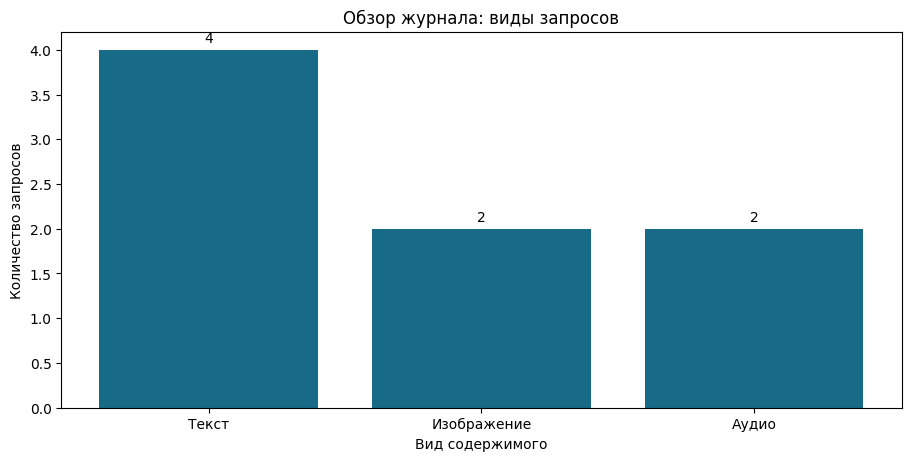

In [25]:
def build_overview(table):
    preview = table.loc[:, ['task_id', 'kind', 'status']].copy()
    counts = table['kind'].value_counts(sort=False)
    heights = counts.to_numpy(dtype=np.int64, copy=True)

    figure, axis = plt.subplots()
    columns = axis.bar(counts.index, heights, color='#176B87')
    axis.bar_label(columns, padding=3)
    axis.set(
        title='Обзор журнала: виды запросов',
        xlabel='Вид содержимого', ylabel='Количество запросов',
    )
    return preview, heights, figure


report_table, report_values, report_figure = build_overview(tasks)
display(report_table)
print('Тип высот:', type(report_values))
print('Форма высот:', report_values.shape)
plt.show()

**Разбор входа и подготовки данных.**

- `def build_overview(table):` определяет функцию с одним параметром `table`. При вызове `build_overview(tasks)` этот параметр обозначает переданный журнал. Тело функции выделено отступом; вложенный многострочный вызов сохраняет тот же смысл отступов.
- `table.loc[:, ['task_id', 'kind', 'status']]` выбирает все строки через `:` и три именованных столбца через список. `.copy()` создаёт отдельную таблицу просмотра, сохранённую в локальной переменной `preview`.
- `table['kind'].value_counts(sort=False)` создаёт Series количества запросов каждого вида. Подписи категорий сохраняются в её `.index`, количества — в значениях.
- `.to_numpy(dtype=np.int64, copy=True)` возвращает независимый массив NumPy с целыми высотами. Параметр `dtype` задаёт тип, `copy=True` — копирование значений. Локальное имя `heights` описывает назначение массива в рисунке.

**Разбор рисунка и возвращаемых объектов.**

- `plt.subplots()` создаёт `figure` и `axis` внутри функции. Метод `.bar(...)` строит столбцы по подписям и массиву высот; строковый `color` задаёт общий цвет. Его результат сохраняется в `columns`, чтобы `.bar_label(columns, padding=3)` мог добавить числа над столбцами.
- `.set(...)` принимает тексты заголовка и подписей осей. Все они относятся к области `axis`. Дополнительная таблица для рисования не создаётся, потому что подписи и высоты уже подготовлены.
- `return preview, heights, figure` возвращает три объекта как один кортеж. Запятые собирают значения по порядку. Сам `return` не выводит таблицу и рисунок на экран.
- `report_table, report_values, report_figure = build_overview(tasks)` вызывает функцию и распаковывает результаты в том же порядке. Эти имена снаружи независимы от локальных имён внутри; `preview`, `counts`, `heights`, `figure`, `axis` как отдельные локальные имена снаружи недоступны.
- `display(report_table)` показывает возвращённую таблицу. `type(report_values)` подтверждает тип массива: `numpy.ndarray`. Атрибут `.shape` сообщает форму массива из трёх высот. Два вызова `print(...)` показывают эти сведения вместе с подписями.
- `plt.show()` показывает созданный рисунок. Сам объект также сохранён в `report_figure`, поэтому к нему можно обращаться отдельно — например, использовать его метод `.savefig(...)`, как в предыдущем примере.

Таблица содержит записи и имена полей, массив — только готовые высоты в согласованном порядке, рисунок — столбцы и оформление. Результаты доступны программе как объекты, а не только как изображённый под ячейкой вывод.